In [ ]:
import os
import random
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torchvision.models import resnet50
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import kagglehub

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [ ]:
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print("Dataset path:", path)

data_root = Path(path)
base_dir = data_root / "PetImages"

cat_dir = base_dir / "Cat"
dog_dir = base_dir / "Dog"


Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Dataset path: /kaggle/input/dog-and-cat-classification-dataset


In [ ]:
image_size = 224
batch_size = 64
num_workers = 4 if torch.cuda.is_available() else 2

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225]),
])


In [ ]:
# ============================================================
# 5. Create train, val, test splits
# ============================================================
# Load full dataset
full_dataset = ImageFolder(base_dir, transform=train_transform)
all_indices = np.arange(len(full_dataset))
all_targets = np.array(full_dataset.targets)

# === 1️⃣ Create test set first ===
test_size = 624
test_idx, remaining_idx = train_test_split(
    all_indices,
    test_size=len(all_indices)-test_size,
    stratify=all_targets,
    random_state=42
)

# === 2️⃣ Create val set next ===
val_size = 522
remaining_targets = all_targets[remaining_idx]
val_idx, train_idx = train_test_split(
    remaining_idx,
    test_size=len(remaining_idx)-val_size,
    stratify=remaining_targets,
    random_state=42
)

# Train set will automatically have the rest
train_idx = train_idx[:2413]  # Ensure exact size
val_idx   = val_idx[:269]     # Ensure exact size
test_idx  = test_idx[:624]    # Ensure exact size

# Subset datasets
train_dataset = Subset(full_dataset, train_idx)
val_dataset   = Subset(
    ImageFolder(base_dir, transform=eval_transform),
    val_idx
)
test_dataset  = Subset(
    ImageFolder(base_dir, transform=eval_transform),
    test_idx
)

print("\nFINAL SPLITS")
print(f"Train size: {len(train_dataset)}")
print(f"Val size:   {len(val_dataset)}")
print(f"Test size:  {len(test_dataset)}")



FINAL SPLITS
Train size: 4694
Val size:   522
Test size:  624


In [ ]:
train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=num_workers
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
backbone = resnet50(pretrained=False)
backbone.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
backbone.maxpool = nn.Identity()
feat_dim = backbone.fc.in_features
backbone.fc = nn.Identity()

ckpt_path = hf_hub_download(
    repo_id="edadaltocg/resnet50_simclr_cifar100",
    filename="pytorch_model.bin"
)

state_dict = torch.load(ckpt_path, map_location="cpu")
state_dict = {
    k.replace("backbone.", ""): v
    for k, v in state_dict.items()
    if k.replace("backbone.", "") in backbone.state_dict()
}

backbone.load_state_dict(state_dict, strict=False)
backbone = backbone.to(device)
print("✅ CIFAR SimCLR backbone loaded")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


✅ CIFAR SimCLR backbone loaded


In [ ]:
class LinearEvalModel(nn.Module):
    def __init__(self, backbone, feature_dim, num_classes):
        super().__init__()
        self.backbone = backbone
        for p in self.backbone.parameters():
            p.requires_grad = False
        self.classifier = nn.Linear(feature_dim, num_classes)

    def forward(self, x):
        return self.classifier(self.backbone(x))

model = LinearEvalModel(backbone, feat_dim, num_classes).to(device)

In [ ]:
train_targets = np.array([full_dataset.targets[i] for i in train_idx])

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=1e-3, weight_decay=1e-6
)


In [ ]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)
    return total_loss / total, correct / total

In [ ]:
epochs = 6
train_losses, val_losses = [], []

start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)
        loss = criterion(model(xb), yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pbar.set_postfix(train_loss=running_loss / (pbar.n + 1))

    train_loss = running_loss / len(train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}: "
          f"Train Loss={train_loss:.4f}, "
          f"Val Loss={val_loss:.4f}, "
          f"Val Acc={val_acc:.4f}")

total_time = time.time() - start_time

print("\n==============================")
print(f"Total training time: {total_time/60:.2f} minutes")
print(f"Avg time / epoch: {total_time/epochs:.2f} seconds")
print("==============================\n")

Epoch 1/6: 100%|██████████| 74/74 [03:48<00:00,  3.09s/it, train_loss=0.645]


Epoch 1: Train Loss=0.6455, Val Loss=0.6052, Val Acc=0.7452


Epoch 2/6: 100%|██████████| 74/74 [03:47<00:00,  3.07s/it, train_loss=0.582]


Epoch 2: Train Loss=0.5822, Val Loss=0.5586, Val Acc=0.7586


Epoch 3/6: 100%|██████████| 74/74 [03:47<00:00,  3.07s/it, train_loss=0.548]


Epoch 3: Train Loss=0.5478, Val Loss=0.5278, Val Acc=0.7835


... (2 outputs left out)

Epoch 5/6: 100%|██████████| 74/74 [03:47<00:00,  3.08s/it, train_loss=0.502]


Epoch 5: Train Loss=0.5018, Val Loss=0.4902, Val Acc=0.8008


Epoch 6/6: 100%|██████████| 74/74 [03:47<00:00,  3.07s/it, train_loss=0.49]


Epoch 6: Train Loss=0.4903, Val Loss=0.4787, Val Acc=0.8008

Total training time: 25.21 minutes
Avg time / epoch: 252.11 seconds



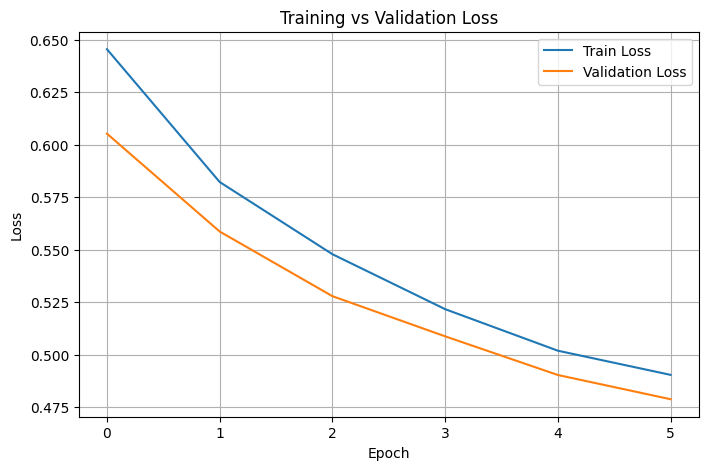

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.4736
Test Accuracy: 0.8093


In [ ]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        preds = model(xb).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))



Classification Report:

              precision    recall  f1-score   support

         Cat       0.82      0.79      0.81       312
         Dog       0.80      0.83      0.81       312

    accuracy                           0.81       624
   macro avg       0.81      0.81      0.81       624
weighted avg       0.81      0.81      0.81       624



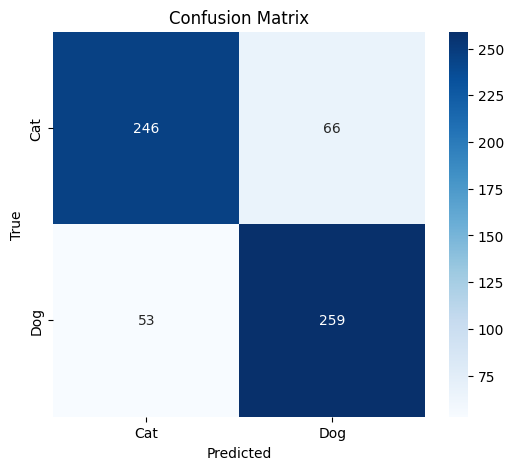

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names,
            yticklabels=class_names,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
